# Grape comparison results

This notebook only reads saved results, so it opens without rebuilding any data. To change or add comparisons, edit `run_grape_differences.py` and run it (about 7 minutes). `grape_differences.ipynb` explains the method and how we checked it.

Everything is scored on validation reviews, and the test split hasn't been touched. Most comparisons ran on all reviews and on only the reviews that name a taster, and we only trust patterns that show up in both.

In [1]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import pandas as pd

import grape_differences as gd

pd.set_option("display.max_columns", 40, "display.max_rows", 120, "display.width", 220)

scores = pd.read_csv("results/grape_difference_scores.csv")
words = pd.read_csv("results/grape_difference_top_words.csv.gz")
transfers = pd.read_csv("results/grape_transfer_scores.csv")
small_tests = pd.read_csv("results/grape_same_reviewer_scores.csv")
small_words = pd.read_csv("results/grape_same_reviewer_top_words.csv")
within = pd.read_csv("results/grape_within_reviewer_scores.csv")
within_words = pd.read_csv("results/grape_within_reviewer_top_words.csv")


def show_pair(grape_a, grape_b, place, place_b=None, run="grid", n=12):
    """Any saved comparison in one line: its scores, then its top words for each side."""
    pair_scores, table = gd.look_up_pair(scores, words, grape_a, grape_b, place, place_b, run)
    display(pair_scores[["reviews_used", "n_train_per_side", "train_accuracy", "val_accuracy", "val_accuracy_sd", "val_auc"]])
    for side, side_words in table.groupby("favors", sort=False):
        display(side_words.head(n).reset_index(drop=True))


scores.groupby(["run", "level", "reviews_used"]).size().unstack()

reviews_used       all  named_taster
run      level                      
grid     all       351           351
         country   313           214
         province  165            83
near_far country    93            48
planned  province    6             6

## What actually separates reviews

Most countries are covered by one main reviewer, so a difference between two countries could just be two writing styles. These small tests pull that apart by holding things fixed, and all of them use 80 reviews per side so they can be compared.

Writing style is the strongest signal by far. The grape comes next, then the country. The control splits one reviewer's grape in half at random, and it lands right at 0.50, so the setup isn't finding differences that aren't there.

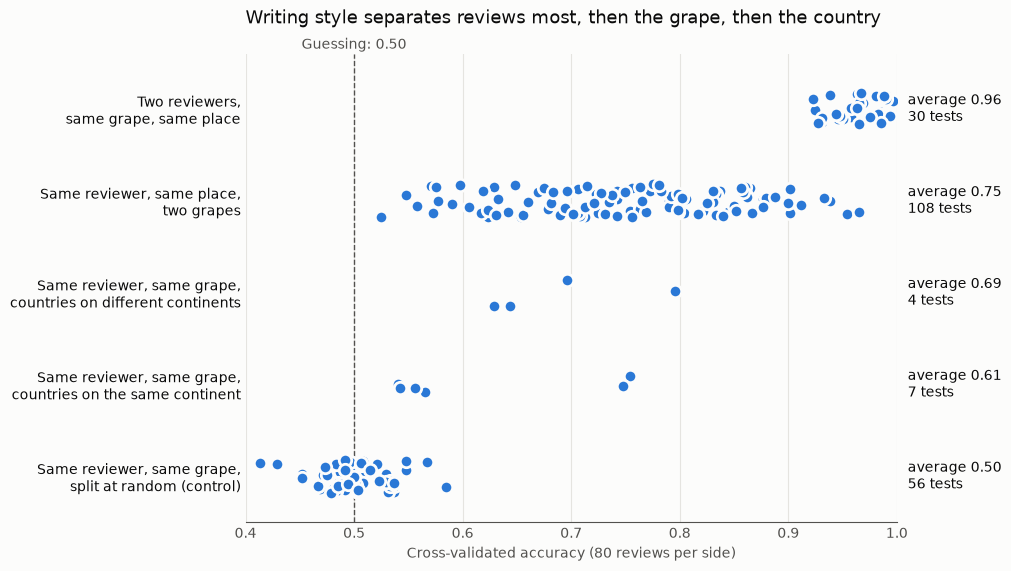

In [2]:
gd.plot_small_tests(pd.concat([small_tests, within]), "Writing style separates reviews most, then the grape, then the country")
plt.show()

In [3]:
# Words that mark each reviewer: top-list appearances across the two-reviewer tests.
marks = small_words[small_words["test"].str.startswith("two") & small_words["in_top_runs"].ge(2)]
marks = marks.assign(reviewer=marks["reviewer_a"].where(marks["favors"].eq("a"), marks["reviewer_b"]))
(marks.groupby("reviewer")["term"].agg(lambda terms: ", ".join(terms.value_counts().head(10).index)).to_frame("most repeated words"))

,most repeated words
reviewer,
Anne Krebiehl MW,"nose, freshness, lovely, peel, lemon, juicy, c..."
Jim Gordon,"texture, like, medium_bodied, good, firm, full..."
Matt Kettmann,"nose, bottling, touch, crushed, dried, blueber..."
Paul Gregutt,"hint, mix, scent, cassis, berry, young, herbal..."
Roger Voss,"acidity, character, ready, spice, texture, ful..."
Sean P. Sullivan,"followed, spice, lead, herb, sense, feel, vani..."
Virginie Boone,"oak, full_bodied, leather, juicy, leathery, so..."


## Do reviews describe grapes differently? One reviewer, one place, two grapes

This is the most direct test of our question, because writing style and place are both fixed. Almost every pair separates clearly, so grape differences are real in the language. The amount varies: whites separate more easily than reds, and Cabernet Sauvignon vs Merlot stays hard. Most of these pairs are from California and Washington, so this speaks mainly to US wines.

In [4]:
grapes = within[within["kind"].ne("control")]
control = within[within["kind"].eq("control")]
display(within.groupby("test")["fixed_accuracy"].agg(["size", "mean", "min", "max"]).round(3))
print(f"Grape pairs with p <= 0.05: {grapes['p_value'].le(0.05).sum()} of {len(grapes)}. Controls: {control['p_value'].le(0.05).sum()} of {len(control)}.")
print("With one reviewer vs with reviewers mixed, same size:")
display(grapes[["fixed_accuracy", "mixed_named_accuracy", "mixed_all_accuracy"]].mean().round(3).to_frame("average accuracy"))
columns = ["kind", "grape_a", "grape_b", "reviewer", "place", "fixed_accuracy", "p_value", "n_full", "full_accuracy"]
ranked_within = grapes.sort_values("fixed_accuracy")[columns].reset_index(drop=True)
display(ranked_within.head(8))
ranked_within.tail(8)

,size,mean,min,max
test,,,,
"same reviewer, same grape, random split",56,0.501,0.413,0.585
"same reviewer, same place, two grapes",108,0.754,0.525,0.965


Grape pairs with p <= 0.05: 100 of 108. Controls: 0 of 56.
With one reviewer vs with reviewers mixed, same size:


,average accuracy
fixed_accuracy,0.754
mixed_named_accuracy,0.734
mixed_all_accuracy,0.735


,kind,grape_a,grape_b,reviewer,place,fixed_accuracy,p_value,n_full,full_accuracy
0,whites,Pinot Blanc,Pinot Gris,Paul Gregutt,Oregon,0.525,0.307,84.0,0.548
1,reds,Cabernet Sauvignon,Merlot,Jim Gordon,California,0.548,0.208,81.0,0.570
2,reds,Cabernet Franc,Merlot,Anna Lee C. Iijima,New York,0.558,0.099,87.0,0.561
3,reds,Cabernet Sauvignon,Merlot,Paul Gregutt,Washington,0.571,0.218,298.0,0.593
4,reds,Cabernet Sauvignon,Merlot,Matt Kettmann,California,0.573,0.099,91.0,0.568
5,reds,Cabernet Franc,Merlot,Virginie Boone,California,0.575,0.119,93.0,0.602
6,reds,Cabernet Sauvignon,Merlot,Virginie Boone,California,0.577,0.040,251.0,0.651
7,reds,Cabernet Franc,Pinot Noir,Anna Lee C. Iijima,New York,0.590,0.059,116.0,0.608


,kind,grape_a,grape_b,reviewer,place,fixed_accuracy,p_value,n_full,full_accuracy
100,reds,Pinot Noir,Syrah,Matt Kettmann,California,0.900,0.01,419.0,0.914
101,reds,Barbera,Nebbiolo,Kerin O’Keefe,Piedmont,0.902,0.01,179.0,0.907
102,reds,Petite Sirah,Pinot Noir,Jim Gordon,California,0.902,0.01,113.0,0.904
103,reds,Petite Sirah,Pinot Noir,Virginie Boone,California,0.912,0.01,138.0,0.908
104,whites,Gewürztraminer,Riesling,Anne Krebiehl MW,Alsace,0.933,0.01,169.0,0.945
105,whites,Gewürztraminer,Pinot Gris,Anne Krebiehl MW,Alsace,0.938,0.01,169.0,0.943
106,whites,Pinot Gris,Sauvignon Blanc,Kerin O’Keefe,Northeastern Italy,0.954,0.01,145.0,0.948
107,whites,Chardonnay,Riesling,Sean P. Sullivan,Washington,0.965,0.01,138.0,0.962


### Do different reviewers agree?

Some pairs are covered by more than one reviewer in the same place, so we can check whether they independently use the same words. This is the strongest evidence behind any word list: `agreed_for_a` and `agreed_for_b` are words at least two reviewers lean the same way on. Nearly all shared words point the same way.

Some reviewers also separate grapes more than others do. Sean P. Sullivan scores higher than Paul Gregutt on every Washington pair they share, at the same sample size.

In [5]:
agreement = gd.reviewer_agreement(within_words)
print(f"Across {len(agreement)} pairs: {agreement['words_agreed'].sum()} words agreed, {agreement['words_opposite'].sum()} words leaned opposite ways")
with pd.option_context("display.max_colwidth", 90):
    display(agreement.sort_values("words_agreed", ascending=False).reset_index(drop=True))

Across 26 pairs: 196 words agreed, 27 words leaned opposite ways


,place,grape_a,grape_b,reviewers,agreed_for_a,agreed_for_b,words_agreed,words_opposite
0,California,Pinot Noir,Syrah,3,"cherry, red_cherry, tea, strawberry, acidity, black_tea, raspberry, forest_floor, fore...","pepper, blackberry, black_pepper, meaty, blueberry",17,0
1,California,Cabernet Sauvignon,Pinot Noir,3,"blackberry, chocolate, currant, dark_chocolate, pepper, soft, tannin, cedar, tobacco","tea, black_tea, cherry, earthy, raspberry, rhubarb, rose, strawberry",17,1
2,California,Merlot,Pinot Noir,3,"blackberry, chocolate, cedar, leather, syrup, tannin, tobacco","color, cranberry, earthy, pomegranate, rose, strawberry, tea, vineyard",15,0
3,California,Cabernet Sauvignon,Syrah,3,"black_cherry, cedar, cherry, chocolate, currant, pencil, red_cherry, tannin, tobacco","pepper, boysenberry, meaty, white, white_pepper",14,1
4,California,Cabernet Sauvignon,Zinfandel,3,"black, black_currant, black_olive, cedar, currant, olive, tannin","strawberry, sweet, berry, blackberry, raspberry, spice, wild",14,3
5,California,Petite Sirah,Pinot Noir,2,"big, black_pepper, blackberry, blueberry, chocolate, pepper, variety","acidity, black_cherry, cherry, cranberry, tea",12,1
6,California,Chardonnay,Sauvignon Blanc,3,"butter, nutmeg, oak, pear, rich, vanilla","grapefruit, grass, grassy, melon, pepper, refreshing",12,1
7,California,Pinot Noir,Zinfandel,3,"cranberry, black_tea, cherry, pomegranate, tea","blackberry, chocolate, pepper, berry, black_pepper, plum, sweet",12,4
8,Washington,Chardonnay,Riesling,2,"barrel, oak, pineapple, toast","apricot, dry, off_dry, orange, peach, sweet",10,0
9,California,Syrah,Zinfandel,3,"pepper, dark, meaty, violet","cinnamon, juicy, soft, spice, strawberry, sweet",10,2


In [6]:
# The same pair by different reviewers.
shared = grapes[grapes.groupby(["place", "grape_a", "grape_b"])["reviewer"].transform("nunique").ge(2)]
shared.pivot_table(index=["place", "grape_a", "grape_b"], columns="reviewer", values="fixed_accuracy").round(2)

reviewer                                       Anne Krebiehl MW  Jim Gordon  Matt Kettmann  Paul Gregutt  Roger Voss  Sean P. Sullivan  Virginie Boone
place      grape_a            grape_b                                                                                                                 
Alsace     Gewürztraminer     Pinot Gris                   0.94         NaN            NaN           NaN        0.63               NaN             NaN
                              Riesling                     0.93         NaN            NaN           NaN        0.88               NaN             NaN
           Pinot Gris         Riesling                     0.88         NaN            NaN           NaN        0.84               NaN             NaN
California Cabernet Sauvignon Merlot                        NaN        0.55           0.57           NaN         NaN               NaN            0.58
                              Petite Sirah                  NaN        0.76            NaN           NaN         NaN               NaN            0.78
                              Pinot Noir                    NaN        0.71           0.87           NaN         NaN               NaN            0.86
                              Syrah                         NaN        0.63           0.75           NaN         NaN               NaN            0.83
                              Zinfandel                     NaN        0.65           0.71           NaN         NaN               NaN            0.76
           Chardonnay         Sauvignon Blanc               NaN        0.80           0.78           NaN         NaN               NaN            0.80
           Merlot             Petite Sirah                  NaN        0.84            NaN           NaN         NaN               NaN            0.68
                              Pinot Noir                    NaN        0.71           0.85           NaN         NaN               NaN            0.82
                              Syrah                         NaN        0.69           0.81           NaN         NaN               NaN            0.73
                              Zinfandel                     NaN        0.68           0.70           NaN         NaN               NaN            0.70
           Petite Sirah       Pinot Noir                    NaN        0.90            NaN           NaN         NaN               NaN            0.91
                              Syrah                         NaN        0.65            NaN           NaN         NaN               NaN            0.66
                              Zinfandel                     NaN        0.80            NaN           NaN         NaN               NaN            0.71
           Pinot Noir         Syrah                         NaN        0.74           0.90           NaN         NaN               NaN            0.80
                              Zinfandel                     NaN        0.76           0.76           NaN         NaN               NaN            0.86
           Syrah              Zinfandel                     NaN        0.68           0.80           NaN         NaN               NaN            0.72
Washington Cabernet Sauvignon Malbec                        NaN         NaN            NaN          0.61         NaN              0.77             NaN
                              Merlot                        NaN         NaN            NaN          0.57         NaN              0.72             NaN
                              Syrah                         NaN         NaN            NaN          0.62         NaN              0.80             NaN
           Chardonnay         Riesling                      NaN         NaN            NaN          0.86         NaN              0.96             NaN
           Malbec             Merlot                        NaN         NaN            NaN          0.64         NaN              0.74             NaN
                              Syrah                         NaN         Na

## Same reviewer, same grape, two countries

These are the cleanest country comparisons we have, because writing style stays fixed. There are only 11, so they're evidence, not proof. Most same-continent pairs aren't clearly different from guessing, while the different-continent pairs all are. Riesling from Austria and France is the exception: it's on one continent, but it's clearly separable for both reviewers who cover it.

In [7]:
same_reviewer = small_tests[small_tests["test"].str.startswith("same")]
same_reviewer.sort_values(["kind", "fixed_accuracy"])[
    ["kind", "grape", "reviewer_a", "place_a", "place_b", "fixed_accuracy", "fixed_accuracy_sd", "p_value", "n_full", "full_accuracy"]
].reset_index(drop=True)

,kind,grape,reviewer_a,place_a,place_b,fixed_accuracy,fixed_accuracy_sd,p_value,n_full,full_accuracy
0,far,Pinot Noir,Anna Lee C. Iijima,Germany,US,0.629,0.036,0.030,86,0.618
1,far,Riesling,Anna Lee C. Iijima,Germany,US,0.644,0.027,0.010,541,0.716
2,far,Syrah,Joe Czerwinski,Australia,France,0.696,0.047,0.010,108,0.710
3,far,Riesling,Joe Czerwinski,Australia,Germany,0.796,0.038,0.010,91,0.796
4,near,Pinot Noir,Joe Czerwinski,Australia,New Zealand,0.540,0.053,0.178,98,0.544
5,near,Cabernet Sauvignon,Michael Schachner,Argentina,Chile,0.540,0.079,0.139,429,0.592
6,near,Chardonnay,Michael Schachner,Argentina,Chile,0.542,0.013,0.248,230,0.563
7,near,Malbec,Michael Schachner,Argentina,Chile,0.556,0.013,0.109,109,0.589
8,near,Chardonnay,Joe Czerwinski,Australia,New Zealand,0.565,0.019,0.119,87,0.567
9,near,Riesling,Roger Voss,Austria,France,0.748,0.030,0.010,176,0.795


In [8]:
# The words behind each one. Label terms like kabinett and spätlese are real, but they name a wine style rather than describe a taste.
tops = small_words[small_words["test"].str.startswith("same") & small_words["in_top_runs"].ge(2)]
(tops.groupby(["grape", "reviewer_a", "place_a", "place_b", "favors"], sort=False)["term"]
 .agg(lambda terms: ", ".join(terms.head(8))).unstack("favors").rename(columns={"a": "leans toward place_a", "b": "leans toward place_b"}))

favors                                                                                    leans toward place_a                               leans toward place_b
grape              reviewer_a         place_a   place_b                                                                                                          
Pinot Noir         Anna Lee C. Iijima Germany   US           nuanced, complex, balanced, supple, lend, back...  rustic, medium_bodied, strawberry, dry, sour_c...
                   Joe Czerwinski     Australia New Zealand  cola, cedar, earthy, coffee, rather, good, lea...  mouthwatering, full_bodied, rose, still, style...
Riesling           Anna Lee C. Iijima Germany   US           kabinett, spätlese, auslese, tangerine, saffro...  apple, hint, bright, floral, pressed_apple, pi...
                   Anne Krebiehl MW   Austria   France       streamlined, grapefruit, apricot, zesty, slend...  dry, apple, bright, clean, taut, freshness, ea...
                   Joe Czerwinski     Australia Germany      lime, medium_bodied, dry, long, year, austere,...  sweet, minerality, mineral, lush, slate, dried...
                   Roger Voss         Austria   France       screwcap, year, least, vineyard, fruit, delici...  full, steely, ready, dry, tight, fruity, fragr...
Chardonnay         Joe Czerwinski     Australia New Zealand  vanilla, peach, plush, lemon, melon, modest, m...  river, year, long, oak, hill, showing, yet, cu...
                   Michael Schachner  Argentina Chile        apricot, floral, fleshy, scent, lychee, dusty,...  corn, green, minerally, bland, resiny, oaky, p...
Syrah              Joe Czerwinski     Australia France       mint, vanilla, creamy, feature, berry, alcohol...  northern, approachable, cuvée, medium_bodied, ...
Cabernet Sauvignon Michael Schachner  Argentina Chile        chewy, licorice, stewy, fairly, syrupy, tastin...  olive, cassis, rubbery, round, nose, eucalyptu...
Malbec             Michael Schachner  Argentina Chile        baked, red_fruit, tomato, spicy, chocolate, de...  herbal, choppy, work, black_fruit, herbal_berr...

## Same grape, near and far countries

On all reviewers, the gap between near and far mostly disappears once the sides have different top reviewers: everything scores high. The score only drops when the same reviewer covers both countries, which is the reviewer effect showing up again. These runs are at 140 training reviews per side.

In [9]:
near_far = scores[scores["run"].eq("near_far")]
(near_far.groupby(["reviews_used", "same_top_reviewer", "kind"])["val_accuracy"]
 .agg(["size", "mean", "min", "max"]).round(3))

size   mean    min    max
reviews_used same_top_reviewer kind                           
all          False             far     81  0.918  0.728  0.994
                               near     6  0.946  0.906  0.989
             True              far      2  0.778  0.767  0.789
                               near     4  0.624  0.550  0.722
named_taster False             far     41  0.951  0.839  1.000
                               near     3  0.981  0.978  0.983
             True              far      1  0.761  0.761  0.761
                               near     3  0.628  0.550  0.778

## Does a model travel?

Each row is a model trained on a grape pair in one country and scored on another country's reviews, next to a model trained in that country on the same number of reviews. `cost_of_moving` is the difference.

Models usually keep some skill but lose a good share of it, so part of what separates two grapes carries across countries and part is local. Reviewers change along with the country in nearly all of these, so we can't say how much of the loss is the place and how much is the writer.

In [10]:
display(transfers.groupby(["reviews_used", "color"])[["home_accuracy", "travel_accuracy", "local_accuracy", "cost_of_moving"]].mean().round(3))
print(f"Tested better than 0.55 in {transfers['travel_accuracy'].gt(0.55).mean():.0%} of runs; at or below 0.50 in {transfers['travel_accuracy'].le(0.50).mean():.0%}")
columns = ["grape_a", "grape_b", "trained_in", "tested_in", "home_accuracy", "travel_accuracy", "local_accuracy", "cost_of_moving"]
everyone = transfers[transfers["reviews_used"].eq("all")].sort_values("cost_of_moving")
display(everyone.head(6)[columns].reset_index(drop=True))
everyone.tail(6)[columns].reset_index(drop=True)

home_accuracy  travel_accuracy  local_accuracy  cost_of_moving
reviews_used color                                                                
all          red            0.762            0.610           0.762           0.152
             white          0.824            0.667           0.824           0.157
named_taster red            0.757            0.604           0.757           0.153
             white          0.828            0.644           0.828           0.184

Tested better than 0.55 in 89% of runs; at or below 0.50 in 3%


,grape_a,grape_b,trained_in,tested_in,home_accuracy,travel_accuracy,local_accuracy,cost_of_moving
0,Grenache,Tempranillo,US,Spain,0.691,0.664,0.682,0.018
1,Chardonnay,Sauvignon Blanc,Chile,Italy,0.838,0.778,0.827,0.049
2,Cabernet Sauvignon,Merlot,Chile,US,0.687,0.571,0.631,0.060
3,Grenache,Tempranillo,Spain,US,0.682,0.627,0.691,0.064
4,Gewürztraminer,Pinot Gris,US,France,0.796,0.707,0.771,0.064
5,Chardonnay,Sauvignon Blanc,Chile,US,0.838,0.740,0.809,0.069


,grape_a,grape_b,trained_in,tested_in,home_accuracy,travel_accuracy,local_accuracy,cost_of_moving
0,Chardonnay,Pinot Gris,France,Italy,0.880,0.458,0.756,0.298
1,Pinot Gris,Sauvignon Blanc,US,France,0.731,0.598,0.904,0.307
2,Pinot Gris,Sauvignon Blanc,Italy,France,0.816,0.571,0.904,0.333
3,Pinot Noir,Syrah,US,France,0.789,0.562,0.951,0.389
4,Malbec,Syrah,US,France,0.633,0.507,0.922,0.416
5,Pinot Noir,Syrah,Chile,France,0.802,0.533,0.951,0.418


## Within each country

Every pair at the same size: 140 training and 30 validation reviews per grape. That's a small validation set, so look at broad patterns rather than exact values. Countries with only one or two pairs tell us very little.

Same-color pairs tend to score higher in France and Italy than in the US, where grapes are less tied to one region. A French Pinot Noir vs Syrah is also a Burgundy vs Rhône comparison.

In [11]:
grid = scores[scores["run"].eq("grid")]
same_color = grid[grid["kind"].isin(["reds", "whites"])]
(same_color[same_color["place_a"].ne(gd.ALL_COUNTRIES)]
 .groupby(["level", "place_a", "kind", "reviews_used"])["val_accuracy"].agg(["size", "mean"]).round(3)
 .unstack("reviews_used"))

size                mean             
reviews_used                   all named_taster    all named_taster
level    place_a      kind                                         
country  Argentina    reds     1.0          1.0  0.594        0.622
         Australia    reds     1.0          1.0  0.761        0.800
                      whites   1.0          NaN  0.822          NaN
         Austria      whites   1.0          1.0  0.778        0.778
         Chile        reds    10.0         10.0  0.722        0.727
                      whites   1.0          1.0  0.883        0.828
         France       reds    10.0          3.0  0.836        0.752
                      whites  21.0         15.0  0.855        0.880
         Italy        reds     6.0          3.0  0.820        0.813
                      whites  10.0          1.0  0.872        0.967
         New Zealand  whites   1.0          NaN  0.917          NaN
         South Africa whites   1.0          NaN  0.839          NaN
         Spain        reds     1.0          1.0  0.683        0.678
         US           reds    66.0         55.0  0.719        0.737
                      whites  21.0         15.0  0.726        0.787
province California   reds    55.0         21.0  0.757        0.775
                      whites  10.0          6.0  0.769        0.733
         Washington   reds    15.0         10.0  0.699        0.692
                      whites   6.0          3.0  0.834        0.861

In [12]:
# The same pair in three or more countries.
by_country = same_color[same_color["level"].eq("country") & same_color["reviews_used"].eq("all")]
table = by_country.pivot_table(index=["kind", "grape_a", "grape_b"], columns="place_a", values="val_accuracy")
table[table.notna().sum(axis=1).ge(3)].round(2)

place_a                                    Argentina  Australia  Austria  Chile  France  Italy  New Zealand  South Africa  Spain    US
kind   grape_a            grape_b                                                                                                     
reds   Cabernet Sauvignon Syrah                  NaN       0.76      NaN   0.72     NaN    NaN          NaN           NaN    NaN  0.72
       Pinot Noir         Syrah                  NaN        NaN      NaN   0.81    0.95    NaN          NaN           NaN    NaN  0.75
whites Chardonnay         Pinot Gris             NaN        NaN      NaN    NaN    0.87   0.74          NaN           NaN    NaN  0.71
                          Riesling               NaN       0.82      NaN    NaN    0.86    NaN          NaN           NaN    NaN  0.79
                          Sauvignon Blanc        NaN        NaN      NaN   0.88    0.70   0.83         0.92          0.84    NaN  0.73
       Pinot Gris         Sauvignon Blanc        NaN        NaN      NaN    NaN    0.90   0.84          NaN           NaN    NaN  0.68

## All countries together

The easiest pairs are grapes that come almost entirely from different countries, like Gamay (France) vs Nebbiolo (Italy), so those high scores can't be read as a difference in the grape alone. `top_country` shows where each grape mostly comes from.

One of the hardest pairs is a useful clue: Malbec (mostly Argentina) and Tempranillo (mostly Spain) come from different continents, but they share the same main reviewer, Michael Schachner, and score only 0.589.

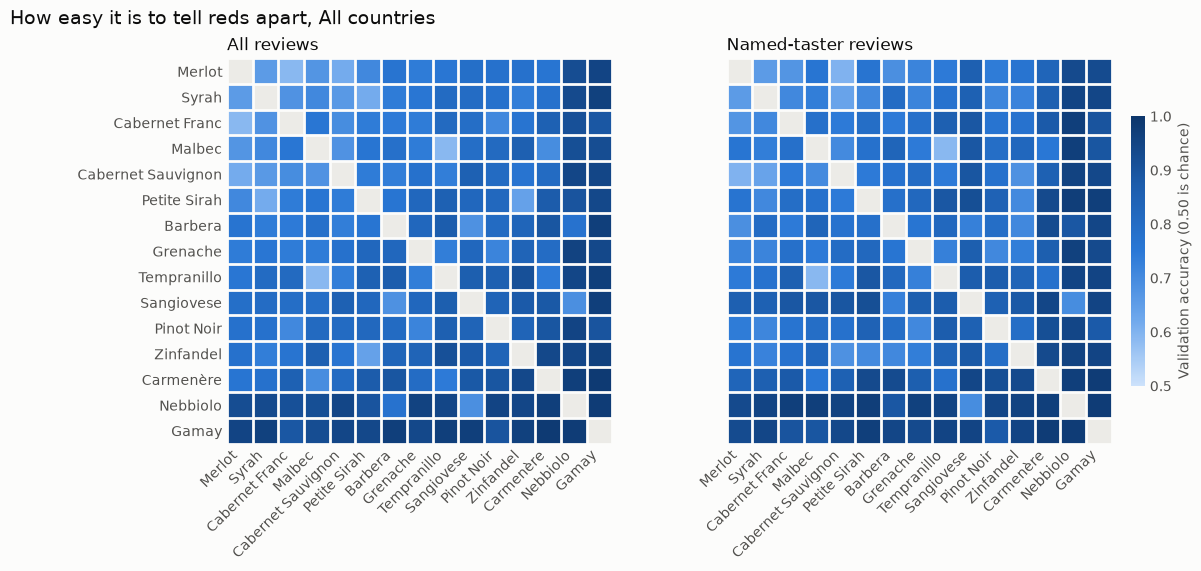

In [13]:
gd.plot_heatmaps(scores, "reds", gd.ALL_COUNTRIES)
plt.show()

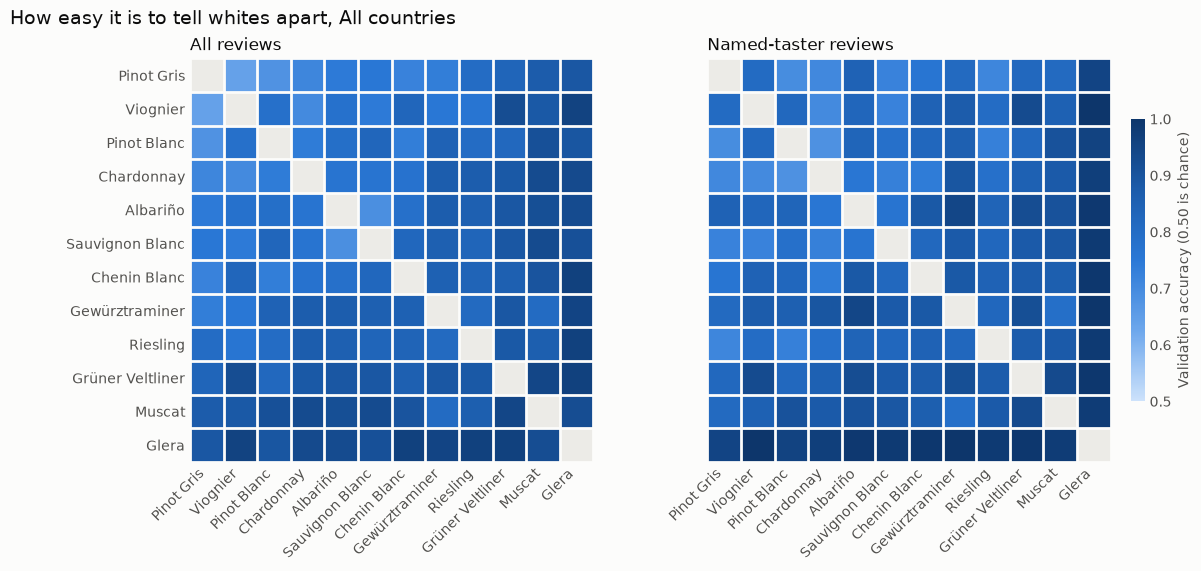

In [14]:
gd.plot_heatmaps(scores, "whites", gd.ALL_COUNTRIES)
plt.show()

In [15]:
world = same_color[same_color["place_a"].eq(gd.ALL_COUNTRIES) & same_color["reviews_used"].eq("all")].sort_values("val_accuracy")
columns = ["kind", "grape_a", "grape_b", "val_accuracy", "top_country_a", "top_country_a_share", "top_country_b", "top_country_b_share"]
display(world.head(8)[columns].reset_index(drop=True))
display(world.tail(8)[columns].reset_index(drop=True))
print(world.assign(mostly_same_country=world["top_country_a"].eq(world["top_country_b"])).groupby("mostly_same_country")["val_accuracy"].agg(["size", "mean"]).round(3))

,kind,grape_a,grape_b,val_accuracy,top_country_a,top_country_a_share,top_country_b,top_country_b_share
0,reds,Malbec,Tempranillo,0.589,Argentina,0.618,Spain,0.828
1,reds,Cabernet Franc,Merlot,0.589,US,0.742,US,0.730
2,reds,Cabernet Sauvignon,Merlot,0.617,US,0.752,US,0.730
3,reds,Petite Sirah,Syrah,0.617,US,0.968,US,0.607
4,whites,Pinot Gris,Viognier,0.639,US,0.481,US,0.774
5,reds,Petite Sirah,Zinfandel,0.639,US,0.968,US,0.958
6,reds,Merlot,Syrah,0.656,US,0.730,US,0.607
7,reds,Cabernet Sauvignon,Syrah,0.661,US,0.752,US,0.607


,kind,grape_a,grape_b,val_accuracy,top_country_a,top_country_a_share,top_country_b,top_country_b_share
0,reds,Gamay,Syrah,0.961,France,0.977,US,0.607
1,reds,Gamay,Zinfandel,0.961,France,0.977,US,0.958
2,reds,Barbera,Gamay,0.967,Italy,0.683,France,0.977
3,reds,Gamay,Tempranillo,0.967,France,0.977,Spain,0.828
4,reds,Carmenère,Nebbiolo,0.967,Chile,0.929,Italy,0.977
5,reds,Gamay,Sangiovese,0.967,France,0.977,Italy,0.873
6,reds,Gamay,Nebbiolo,0.978,France,0.977,Italy,0.977
7,reds,Carmenère,Gamay,0.983,Chile,0.929,France,0.977


                     size   mean
mostly_same_country             
False                 130  0.847
True                   41  0.739


## California, and our planned pairs

We picked the planned pairs before seeing any results. They use every review the smaller side has, so sizes differ. Similar pairs score lower than different ones. Pinot Gris vs Pinot Blanc has under 100 training reviews per side, too few to conclude anything. Pinot Noir from California vs Burgundy has almost entirely different reviewers on each side, so given the reviewer finding above, its high score doesn't show a difference in the wine.

In [16]:
planned = scores[scores["run"].eq("planned")]
(planned.pivot(index=["kind", "grape_a", "grape_b", "place_a", "place_b"], columns="reviews_used", values=["n_train_per_side", "val_accuracy"])
 .sort_values(("val_accuracy", "all"), ascending=False))

n_train_per_side              val_accuracy             
reviews_used                                                                                     all named_taster          all named_taster
kind                    grape_a            grape_b            place_a    place_b                                                           
red vs white            Pinot Noir         Chardonnay         California California           4869.0       1767.0        0.991        0.992
same grape, two regions Pinot Noir         Pinot Noir         California Burgundy             1374.0        999.0        0.983        0.998
different reds          Pinot Noir         Cabernet Sauvignon California California           5512.0       1715.0        0.912        0.877
different whites        Chardonnay         Sauvignon Blanc    California California           1798.0        660.0        0.847        0.831
similar reds            Cabernet Sauvignon Merlot             California California           1512.0        344.0        0.718        0.594
similar whites          Pinot Gris         Pinot Blanc        Oregon     Oregon                 94.0         70.0        0.483        0.560

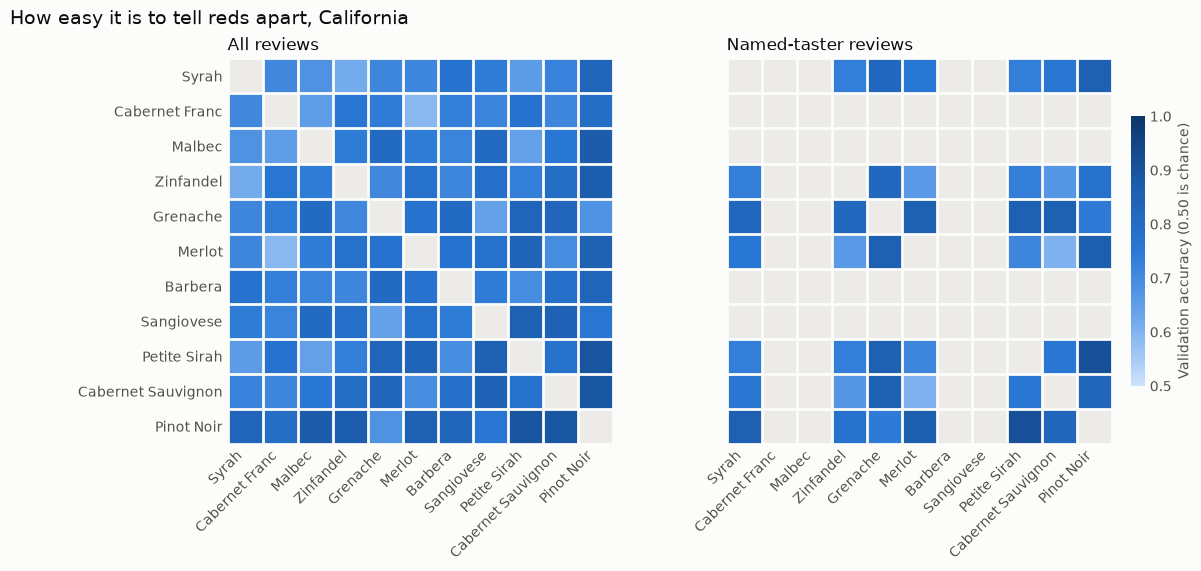

In [17]:
gd.plot_heatmaps(scores, "reds", "California")
plt.show()

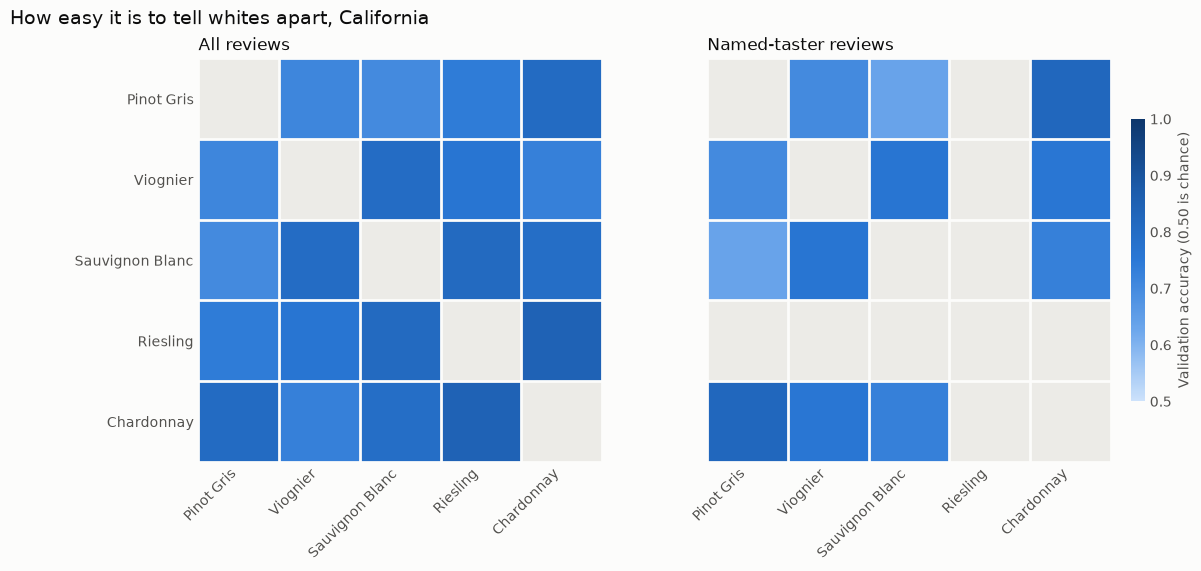

In [18]:
gd.plot_heatmaps(scores, "whites", "California")
plt.show()

In [19]:
display(gd.grape_distinctiveness(scores, "California", "all"))
gd.grape_distinctiveness(scores, "California", "named_taster")

,kind,grape,pairs,average_accuracy,lowest,highest
0,reds,Pinot Noir,10,0.828,0.678,0.900
1,reds,Cabernet Sauvignon,10,0.780,0.694,0.889
2,reds,Petite Sirah,10,0.770,0.644,0.900
3,reds,Sangiovese,10,0.766,0.639,0.850
4,reds,Barbera,10,0.757,0.694,0.833
5,reds,Grenache,10,0.752,0.639,0.833
6,reds,Merlot,10,0.752,0.589,0.850
7,reds,Zinfandel,10,0.750,0.617,0.867
8,reds,Malbec,10,0.740,0.644,0.872
9,reds,Cabernet Franc,10,0.717,0.589,0.794


,kind,grape,pairs,average_accuracy,lowest,highest
0,reds,Pinot Noir,6,0.830,0.744,0.911
1,reds,Grenache,6,0.822,0.744,0.850
2,reds,Petite Sirah,6,0.782,0.711,0.911
3,reds,Syrah,6,0.775,0.733,0.856
4,reds,Cabernet Sauvignon,6,0.743,0.600,0.850
5,reds,Merlot,6,0.739,0.600,0.861
6,reds,Zinfandel,6,0.732,0.661,0.817
7,whites,Chardonnay,3,0.769,0.728,0.822
8,whites,Viognier,3,0.739,0.700,0.761
9,whites,Pinot Gris,3,0.718,0.633,0.822


## Looking up one comparison

`in_both` marks the words that made the top list in most samples, on all reviews and on named-taster reviews. Those are the safe ones to present. The `%` columns use all reviews. Change the names to see any saved pair: pass `run="planned"` for the planned pairs, and `gd.ALL_COUNTRIES` as the place for the worldwide grid.

In [20]:
show_pair("Cabernet Sauvignon", "Merlot", "California", run="planned")

,reviews_used,n_train_per_side,train_accuracy,val_accuracy,val_accuracy_sd,val_auc
2,all,1512,0.853,0.718,0.010,0.797
930,named_taster,344,0.885,0.594,0.028,0.649


,favors,term,in_both,runs_all,runs_named,% of Cabernet Sauvignon,% of Merlot
0,Cabernet Sauvignon,blackberry,True,5.0,3.0,48.6,26.5
1,Cabernet Sauvignon,currant,True,5.0,5.0,30.1,17.2
2,Cabernet Sauvignon,cassis,True,5.0,5.0,15.1,3.2
3,Cabernet Sauvignon,cellar,True,5.0,4.0,7.2,1.9
4,Cabernet Sauvignon,classic,True,5.0,3.0,4.6,0.8
5,Cabernet Sauvignon,full,True,3.0,3.0,3.8,1.6
6,Cabernet Sauvignon,powerful,True,3.0,4.0,3.3,0.7
7,Cabernet Sauvignon,black,False,5.0,NaN,30.9,18.6
8,Cabernet Sauvignon,ripe,False,5.0,NaN,20.3,14.3
9,Cabernet Sauvignon,year,False,5.0,NaN,18.6,7.1


,favors,term,in_both,runs_all,runs_named,% of Cabernet Sauvignon,% of Merlot
0,Merlot,red,True,5.0,3.0,10.8,19.7
1,Merlot,plum,True,5.0,5.0,8.8,13.5
2,Merlot,variety,True,5.0,3.0,1.4,3.2
3,Merlot,cinnamon,True,3.0,5.0,2.4,3.8
4,Merlot,medium_bodied,True,3.0,5.0,1.8,3.8
5,Merlot,cherry,False,5.0,1.0,36.0,58.7
6,Merlot,dry,False,5.0,NaN,23.5,31.9
7,Merlot,black_cherry,False,5.0,NaN,8.6,11.8
8,Merlot,fruity,False,5.0,NaN,4.0,8.0
9,Merlot,nice,False,5.0,NaN,4.0,8.3
